# 07 · Native track: uncertainty, tightening and the risk budget

> **In short:** inside every NMPC solve the current covariances are propagated over the 20-node horizon, projected on the direction to each obstacle and turned into a keep-out radius. Individual and joint risk differ only in how much ε each cell receives.
>
> **Runtime:** about 40 s · **Read alongside:** [Covariance propagation](../2.Code/docs/concepts/covariance-propagation.md) · [Chance constraints](../2.Code/docs/concepts/chance-constraints.md) · [Risk budget](../2.Code/docs/concepts/risk-budget.md)

**You will:**

- look at the covariance horizon of one solve
- compare tightened radii for individual and joint risk
- check the joint budget arithmetic and the post-solve risk certificate

In [1]:
from nbsetup import *

In [2]:
from quadrotor_mpc.application.native.headless import run_headless_episode
from quadrotor_mpc.application.native.telemetry import load_native_recording

SCENARIO = CONFIG / "mujoco_native_ccmpc.yaml"


def run(mode, seed=1001, duration=None):
    episode = run_headless_episode(SCENARIO, mode=mode, seed=seed, duration_s=duration, base_dir=OUTPUT)
    print(f"{mode:13s} {episode.result['termination_reason']}, collision={episode.result['collided']}, "
          f"recording: {episode.recording.name}")
    return load_native_recording(episode.recording)


def column(recording, name):
    return np.array([float(row[name]) if row[name] not in ("", None) else np.nan for row in recording["rows"]])

In [3]:
duration = 2.0 if FAST else 3.0
runs = {mode: run(mode, duration=duration) for mode in ("individual", "joint_uniform")}
names = [item["name"] for item in runs["joint_uniform"]["scenario"]["obstacles"]]
tick = 20  # one second into the episode
dt = runs["joint_uniform"]["scenario"]["simulation"]["mpc_timestep_s"]
nodes = np.arange(21)

individual    duration_reached, collision=False, recording: 20261011T145941Z_ccmpc-mujoco-native-estimated-dynamic-individual


joint_uniform duration_reached, collision=False, recording: 20261011T145951Z_ccmpc-mujoco-native-estimated-dynamic-joint_uniform


## 1 · Uncertainty grows along the horizon

Row 0 is the current belief; later rows are open-loop predictions. Position σ is the square root of
the largest eigenvalue of the 3×3 position block. The three obstacle trackers share the same noise
settings, so their curves coincide.

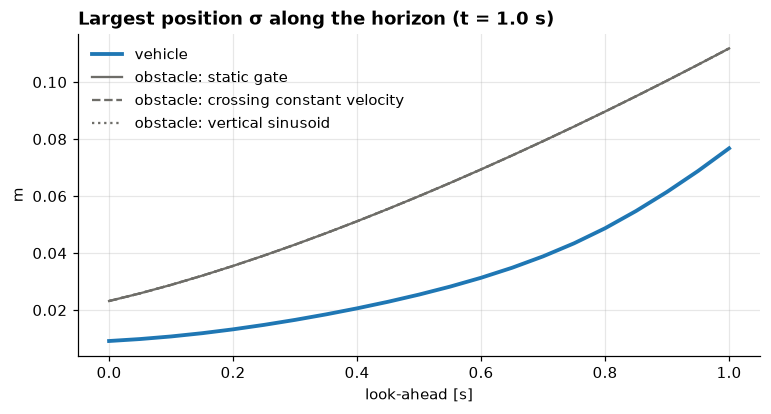

In [4]:
recording = runs["joint_uniform"]
vehicle = recording["predicted_error_covariance_horizons"][tick][:, :3, :3]
obstacle = recording["predicted_obstacle_covariance_horizons"][tick][:, :, :3, :3]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(nodes * dt, np.sqrt(np.linalg.eigvalsh(vehicle)[:, -1]), lw=2.5, label="vehicle")
for j, (name, style) in enumerate(zip(names, ("-", "--", ":"))):
    ax.plot(nodes * dt, np.sqrt(np.linalg.eigvalsh(obstacle[:, j])[:, -1]), ls=style, color=NEUTRAL,
            label=f"obstacle: {name.replace('_', ' ')}")
ax.set(title=f"Largest position σ along the horizon (t = {tick * dt:.1f} s)", xlabel="look-ahead [s]", ylabel="m")
ax.legend()
plt.show()

## 2 · From σ to a keep-out radius

$r_{\text{tight},k,o}=r_{\text{base},o}+\Phi^{-1}(1-\epsilon_{k,o})\,\sigma_{k,o}$. Individual risk uses
$\epsilon=0.05$ per cell; joint risk spreads $\epsilon_{\text{total}}=0.10$ over all $N\cdot n_{obs}$
cells, so each cell gets a much smaller ε and a larger radius.

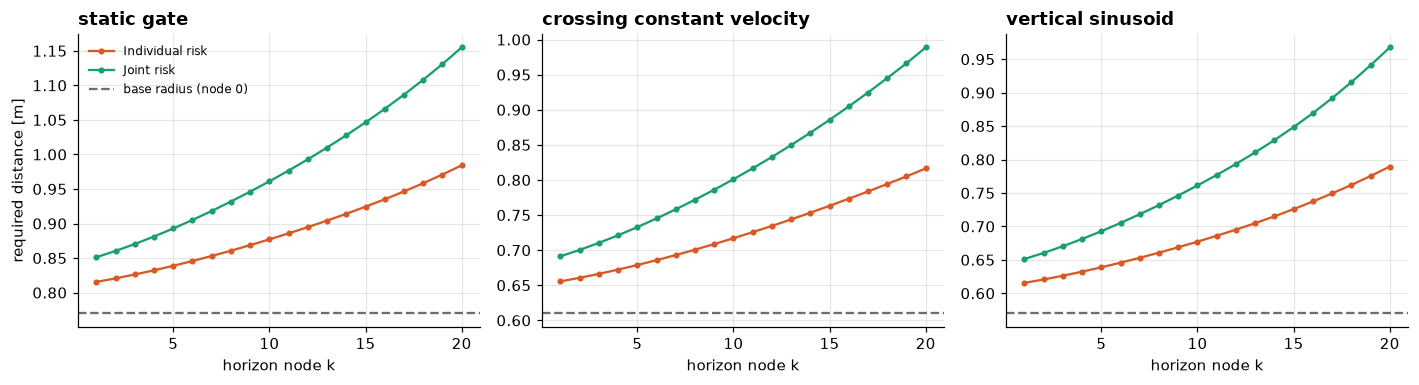

joint: risk per cell 0.0016666666666666668 | node-0 risk 0.0 | total 0.09999999999999999 | quantile 2.935
individual: risk per cell 0.05 | quantile 1.645


In [5]:
from scipy.stats import norm

fig, axes = plt.subplots(1, len(names), figsize=(13, 3.6), sharey=False)
for j, (ax, name) in enumerate(zip(axes, names)):
    for mode, rec in runs.items():
        radius = rec["tightened_safety_radius_horizons"][tick][:, j]
        ax.plot(nodes[1:], radius[1:], "o-", ms=3, color=CONTROLLER_COLORS[mode], label=CONTROLLER_LABELS[mode])
    base = runs["joint_uniform"]["tightened_safety_radius_horizons"][tick][0, j]
    ax.axhline(base, color=NEUTRAL, ls="--", label="base radius (node 0)")
    ax.set(title=name.replace("_", " "), xlabel="horizon node k")
axes[0].set_ylabel("required distance [m]")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

allocation = runs["joint_uniform"]["risk_allocation_horizons"][tick]
print("joint: risk per cell", allocation[1, 0], "| node-0 risk", allocation[0].sum(),
      "| total", allocation.sum(), "| quantile", norm.ppf(1 - allocation[1, 0]).round(3))
print("individual: risk per cell", runs["individual"]["risk_allocation_horizons"][tick][1, 0],
      "| quantile", norm.ppf(1 - runs["individual"]["risk_allocation_horizons"][tick][1, 0]).round(3))
assert np.isclose(allocation.sum(), 0.10) and allocation[0].sum() == 0.0

## 3 · After the solve: slack and the risk certificate

The radii above were computed along the *seed* trajectory. After the solve the controller re-projects
the uncertainty on the optimized trajectory and computes the linearized collision risk of the whole
horizon (`achieved_risk_total`). For joint risk the solve is `CERTIFIED` when that sum stays within
the budget, even if a cell needed a few millimetres of slack. For individual risk the certificate
checks every cell against its own ε = 0.05, so its sum is shown only for comparison.

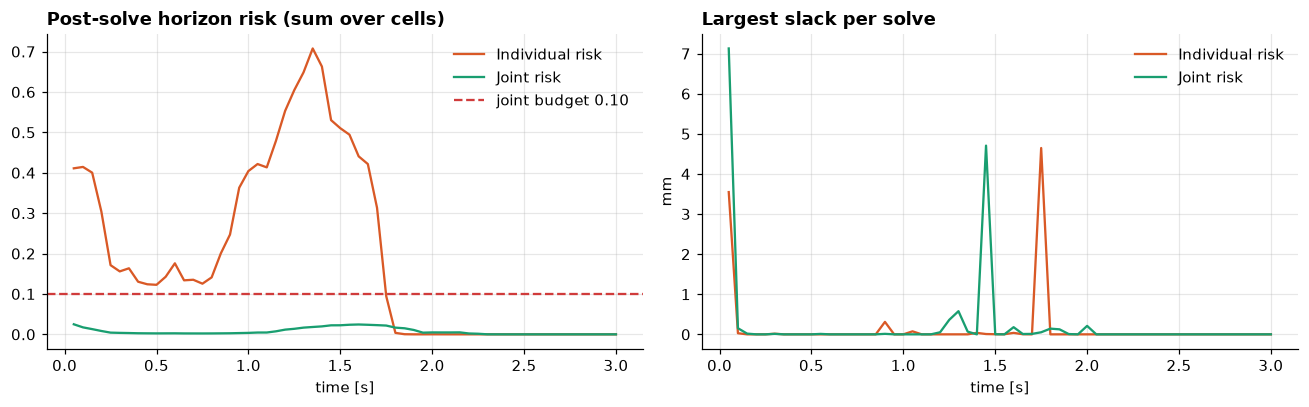

{'CERTIFIED': 60}


In [6]:
fig, (ax_risk, ax_slack) = plt.subplots(1, 2, figsize=(12, 3.8))
for mode, rec in runs.items():
    t = column(rec, "time_s")
    ax_risk.plot(t, column(rec, "achieved_risk_total"), color=CONTROLLER_COLORS[mode], label=CONTROLLER_LABELS[mode])
    ax_slack.plot(t, 1000 * column(rec, "maximum_slack_m"), color=CONTROLLER_COLORS[mode], label=CONTROLLER_LABELS[mode])
ax_risk.axhline(0.10, color=CRITICAL, ls="--", label="joint budget 0.10")
ax_risk.set(title="Post-solve horizon risk (sum over cells)", xlabel="time [s]")
ax_slack.set(title="Largest slack per solve", xlabel="time [s]", ylabel="mm")
ax_risk.legend()
ax_slack.legend()
plt.tight_layout()
plt.show()

statuses = [row["risk_certificate_status"] for row in runs["joint_uniform"]["rows"]]
print({status: statuses.count(status) for status in sorted(set(statuses))})

## Takeaways

- Uncertainty, not geometry, is what makes the chance-constrained controllers keep their distance.
- The joint budget is a union bound over **one** prediction horizon; it is not an episode-wide
  collision probability ([claims and statistics](../2.Code/docs/validation/claims-and-statistics.md)).

---

**Previous:** [06_native_estimation.ipynb](06_native_estimation.ipynb) · **Next:** [08_native_controller_comparison.ipynb](08_native_controller_comparison.ipynb)